# What drives a bad contact — and what to do about it

Four questions, answered from the scored model tables in `data/processed/`:

1. **What drives negative sentiment and low CSAT?** Topic, channel, agent tenure, hold time.
2. **What happened to Team 3?** Their numbers improved sharply in the last two months.
3. **What drives repeat contacts?** The metric that costs the most to get wrong.
4. **So what should change?**

The business write-up is `docs/recommendation.md`. This notebook is the working.

All data is synthetic (see `CLAUDE.md`). Sentiment comes from the RoBERTa scorer;
`docs/validation.md` covers how far it can be trusted — in short, the overall label
runs too negative, and the **end-of-call** score is the reliable one. That matters for
section 3.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
P = ROOT / "data/processed"

# Chart styling. One hue for single-series magnitude; a second only where two
# things are genuinely being compared. Palette validated for colour-vision
# deficiency before use — see powerbi/theme.json.
SURFACE, INK, MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c9c8c3"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK,
    "axes.labelcolor": MUTED, "axes.edgecolor": "#d8d7d2",
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "figure.dpi": 110,
})

In [2]:
# --- Load the star schema and flatten it for analysis --------------------
fact = pd.read_csv(P / "fact_interactions.csv", parse_dates=["start_datetime"])
agent = pd.read_csv(P / "dim_agent.csv")
team = pd.read_csv(P / "dim_team.csv")
topic = pd.read_csv(P / "dim_topic.csv")
channel = pd.read_csv(P / "dim_channel.csv")
sqm = pd.read_csv(P / "fact_sqm_monthly.csv").merge(team[["team_key", "team_name"]], on="team_key")

df = (fact
      .merge(agent[["agent_key", "agent_name", "team_key", "tenure_band",
                    "tenure_days", "is_new_hire", "aht_target_sec"]], on="agent_key")
      .merge(team[["team_key", "team_name"]], on="team_key")
      .merge(topic[["topic_key", "topic_name"]], on="topic_key")
      .merge(channel[["channel_key", "channel_name"]], on="channel_key"))

df["month"] = df["start_datetime"].dt.to_period("M").astype(str)
df["is_negative"] = df["sentiment_label"].eq("negative")
df["hold_minutes"] = df["hold_time_sec"] / 60
df["hold_band"] = pd.cut(df["hold_minutes"], [-0.01, 0.01, 1, 3, 100],
                         labels=["no hold", "under 1 min", "1–3 min", "over 3 min"])
# The validated signal: did the customer sound unhappy AT THE END?
df["ended_badly"] = df["sentiment_end"] < -0.25

sqm["month"] = sqm["month_key"].astype(str).str[:4] + "-" + sqm["month_key"].astype(str).str[4:]

print(f"{len(df):,} contacts · {df['month'].min()} to {df['month'].max()} · "
      f"{df['has_survey_response'].sum()} survey responses")

2,000 contacts · 2026-04 to 2026-10 · 300 survey responses


## 1. What drives a negative contact?

Start with the raw cuts — the view a dashboard would give you.

In [3]:
def rate_by(column, flag="is_negative"):
    out = (df.groupby(column, observed=True)
             .agg(contacts=(flag, "size"), rate=(flag, "mean"))
             .sort_values("rate", ascending=False))
    out["rate"] = (out["rate"] * 100).round(1)
    return out

for col in ["topic_name", "channel_name", "tenure_band", "hold_band"]:
    print(f"── % negative by {col} " + "─" * (46 - len(col)))
    print(rate_by(col).to_string(), "\n")

── % negative by topic_name ────────────────────────────────────
                         contacts  rate
topic_name                             
high bill dispute             207  84.5
outage or service issue       409  82.4
payment arrangement           287  63.8
meter reading                 148  48.0
billing question              309  42.1
move-in/move-out              418  17.7
general enquiry               222  16.7 

── % negative by channel_name ──────────────────────────────────
              contacts  rate
channel_name                
voice             1347  51.0
chat               465  49.7
email              188  47.3 

── % negative by tenure_band ───────────────────────────────────
                    contacts  rate
tenure_band                       
5 years +                 98  75.5
2 - 5 years             1203  54.9
Under 6 months            86  52.3
6 months - 2 years       613  37.2 

── % negative by hold_band ─────────────────────────────────────
             contac

Three things stand out, and one of them is a trap.

- **Topic is enormous.** 84.5% on high bill disputes against 16.7% on general
  enquiries — a 68-point spread.
- **Channel is flat.** 51% / 50% / 47% across voice, chat and email. Whatever is
  going wrong is not about the medium.
- **Tenure looks backwards.** The most experienced band is the *most* negative
  (75.5%), the 6-month-to-2-year band the least (37.2%). That is not credible, so
  it needs checking before it goes anywhere near a slide.

In [4]:
# --- Why the tenure cut is misleading ------------------------------------
# If tenure bands do not handle the same work, comparing their outcomes
# compares the work, not the people.
print("Topic mix within each tenure band (row %):")
print((pd.crosstab(df["tenure_band"], df["topic_name"], normalize="index") * 100)
      .round(0).astype(int).to_string())

print("\nContacts by tenure band × team:")
print(pd.crosstab(df["tenure_band"], df["team_name"]).to_string())

Topic mix within each tenure band (row %):
topic_name          billing question  general enquiry  high bill dispute  meter reading  move-in/move-out  outage or service issue  payment arrangement
tenure_band                                                                                                                                            
2 - 5 years                        6               12                 10              2                21                       33                   14
5 years +                          0                0                 46              0                 0                        0                   54
6 months - 2 years                31               11                  7             15                26                        0                   10
Under 6 months                    51               10                  0             27                 0                       12                    0

Contacts by tenure band × team:
team_name   

There it is. The **5 years +** band sits entirely in Payments & Credit and handles
nothing but high bill disputes (46%) and payment arrangements (54%) — the two
hardest topics in the centre. Their negative rate is their *caseload*, not their
ability.

This is the single most important slide to not show. "Our most experienced agents
are the worst" is a conclusion that would damage trust in both the data and the
people, and it is an artefact of who gets assigned what.

To separate the effects, model them together.

In [5]:
# --- Driver model: each factor holding the others constant ---------------
# Logistic regression, not for prediction but to read the coefficients: it
# answers "what still matters once everything else is accounted for?"
features = pd.get_dummies(df[["topic_name", "channel_name", "team_name"]], drop_first=True)
features["hold_minutes"] = df["hold_minutes"]
features["is_new_hire"] = df["is_new_hire"].astype(int)
features["tenure_years"] = df["tenure_days"] / 365

model = LogisticRegression(max_iter=2000, random_state=42).fit(features, df["is_negative"])
odds = np.exp(pd.Series(model.coef_[0], index=features.columns)).sort_values()

print("Odds ratio for a contact being negative")
print("(1.0 = no effect · above = worse · below = better)\n")
print(odds.round(2).to_string())

Odds ratio for a contact being negative
(1.0 = no effect · above = worse · below = better)

topic_name_general enquiry            0.30
topic_name_move-in/move-out           0.36
team_name_Move In / Move Out          0.86
topic_name_payment arrangement        0.93
tenure_years                          1.04
hold_minutes                          1.04
channel_name_voice                    1.06
team_name_Outage & Emergency          1.08
channel_name_email                    1.08
topic_name_meter reading              1.27
is_new_hire                           1.49
team_name_Payments & Credit           2.56
topic_name_high bill dispute          2.74
topic_name_outage or service issue    5.52


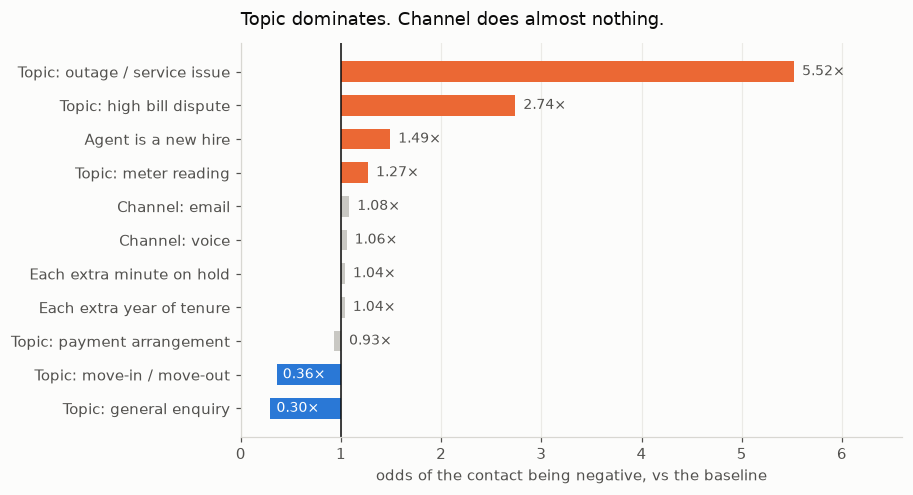

In [6]:
# --- Chart: what actually drives it --------------------------------------
show = odds.drop([c for c in odds.index if c.startswith("team_name_")])
labels = {
    "topic_name_outage or service issue": "Topic: outage / service issue",
    "topic_name_high bill dispute": "Topic: high bill dispute",
    "topic_name_meter reading": "Topic: meter reading",
    "topic_name_payment arrangement": "Topic: payment arrangement",
    "topic_name_move-in/move-out": "Topic: move-in / move-out",
    "topic_name_general enquiry": "Topic: general enquiry",
    "channel_name_voice": "Channel: voice", "channel_name_email": "Channel: email",
    "is_new_hire": "Agent is a new hire", "hold_minutes": "Each extra minute on hold",
    "tenure_years": "Each extra year of tenure",
}
show = show.rename(index=labels).sort_values()

fig, ax = plt.subplots(figsize=(8.4, 4.6))
colours = [ORANGE if v > 1.25 else GREY if 0.8 < v < 1.25 else BLUE for v in show]
ax.barh(range(len(show)), show.values - 1, left=1, color=colours, height=0.62)
ax.axvline(1, color=INK, linewidth=1)

for i, v in enumerate(show.values):
    if v >= 1:
        ax.text(v + 0.08, i, f"{v:.2f}×", va="center", ha="left",
                fontsize=9, color=MUTED)
    elif v < 0.8:
        # These bars extend LEFT toward the axis labels, so the value goes
        # inside the bar rather than outside, where it would collide.
        ax.text(v + 0.06, i, f"{v:.2f}×", va="center", ha="left",
                fontsize=9, color="#ffffff")
    else:
        # Barely-below-1 bars are too short to hold a label; put it on the
        # right with the rest, where there is room.
        ax.text(1.08, i, f"{v:.2f}×", va="center", ha="left",
                fontsize=9, color=MUTED)

ax.set_yticks(range(len(show)), show.index)
ax.set_xlim(0, 6.6)
ax.set_xlabel("odds of the contact being negative, vs the baseline")
ax.set_title("Topic dominates. Channel does almost nothing.",
             fontsize=12, color=INK, pad=12, loc="left")
ax.xaxis.grid(True, color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

Holding everything else constant:

- **An outage call has 5.5× the odds** of going negative; a high bill dispute 2.7×.
  Move-in/move-out and general enquiries sit well below 1 — they are easy work.
- **Channel is ~1.06×. Effectively nothing.** Worth knowing because it kills a
  tempting and expensive idea: moving volume between channels will not fix this.
- **New hires carry 1.49× the odds** — real, worth coaching, and far smaller than
  the topic effect. Once topic is controlled, raw *tenure* does nothing (1.04×),
  which confirms the earlier cut was confounded.
- **Each minute on hold adds about 4%** to the odds. Small per minute, but it
  compounds: a ten-minute hold is roughly 1.5× the odds of no hold at all. **It is
  also the only driver on this list that the centre directly controls.**

You cannot stop customers having high bills. You can decide how long they wait.

### The same cut for CSAT

CSAT only exists for the ~15% who answered the survey, so these numbers rest on
300 responses, not 2,000 contacts — and unhappy customers answer more often. Treat
the ranking as real and the levels as pessimistic.

In [7]:
responders = df[df["has_survey_response"]]
csat = (responders.groupby("topic_name")
        .agg(responses=("is_csat_promoter", "size"),
             csat_pct=("is_csat_promoter", "mean"),
             avg_score=("csat_score", "mean"))
        .sort_values("csat_pct"))
csat["csat_pct"] = (csat["csat_pct"] * 100).round(1)
csat["avg_score"] = csat["avg_score"].round(2)
print("CSAT (% scoring 4–5) by topic, respondents only:")
print(csat.to_string())
print(f"\nOverall: {responders['is_csat_promoter'].mean():.1%} of respondents, "
      f"n={len(responders)}")
print(f"Response rate: {df['has_survey_response'].mean():.1%} — and skewed toward "
      f"the unhappy, so this understates true satisfaction.")

CSAT (% scoring 4–5) by topic, respondents only:
                         responses  csat_pct  avg_score
topic_name                                             
high bill dispute               34      17.6       2.12
outage or service issue         58      22.4       2.52
meter reading                   23      34.8       2.91
payment arrangement             45      40.0       3.04
billing question                52      40.4       3.13
general enquiry                 34      44.1       3.21
move-in/move-out                54      51.9       3.17

Overall: 36.3% of respondents, n=300
Response rate: 15.0% — and skewed toward the unhappy, so this understates true satisfaction.


The CSAT ordering matches the sentiment ordering almost exactly — disputes and
outages at the bottom, move-in/move-out at the top. Two independent measures
agreeing is worth something: it means the sentiment model is picking up the same
thing customers report, even though it reads individual calls too harshly.

## 2. Team 3 — what happened, and is it real?

Move In / Move Out improved sharply from August. Before treating that as a success
to copy, rule out the boring explanations: did the whole centre improve, did their
work get easier, or did they just handle fewer hard calls?

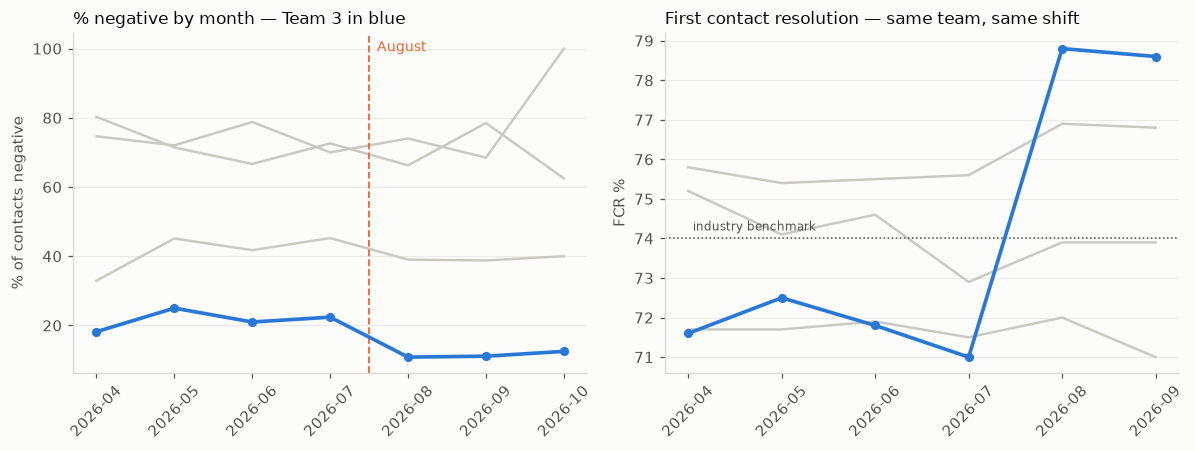

In [8]:
by_month = df.pivot_table(index="month", columns="team_name",
                          values="is_negative", aggfunc="mean") * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

# Highlight the team in question; the other three recede to context.
for name in by_month.columns:
    focus = name == "Move In / Move Out"
    ax1.plot(by_month.index, by_month[name], linewidth=2.4 if focus else 1.6,
             color=BLUE if focus else GREY, marker="o" if focus else None,
             markersize=5, zorder=3 if focus else 1,
             label=name if focus else None)
ax1.axvline(3.5, color=ORANGE, linestyle="--", linewidth=1.2)
ax1.text(3.6, ax1.get_ylim()[1] * 0.95, "August", color=ORANGE, fontsize=9)
ax1.set_title("% negative by month — Team 3 in blue", fontsize=11, color=INK, loc="left")
ax1.set_ylabel("% of contacts negative")
ax1.yaxis.grid(True, color="#ebeae6", linewidth=0.8)
ax1.set_axisbelow(True)
ax1.tick_params(axis="x", rotation=45)

fcr = sqm.pivot_table(index="month", columns="team_name", values="fcr_pct")
for name in fcr.columns:
    focus = name == "Move In / Move Out"
    ax2.plot(fcr.index, fcr[name], linewidth=2.4 if focus else 1.6,
             color=BLUE if focus else GREY, marker="o" if focus else None, markersize=5,
             zorder=3 if focus else 1)
ax2.axhline(74, color=MUTED, linestyle=":", linewidth=1)
ax2.text(0.05, 74.2, "industry benchmark", fontsize=8, color=MUTED)
ax2.set_title("First contact resolution — same team, same shift", fontsize=11,
              color=INK, loc="left")
ax2.set_ylabel("FCR %")
ax2.yaxis.grid(True, color="#ebeae6", linewidth=0.8)
ax2.set_axisbelow(True)
ax2.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

In [9]:
# --- Difference-in-differences: did Team 3 improve, or did everyone? -----
t3 = df[df["team_name"] == "Move In / Move Out"]
rest = df[df["team_name"] != "Move In / Move Out"]

def before_after(frame, column="is_negative"):
    return (frame[frame["month"] < "2026-08"][column].mean(),
            frame[frame["month"] >= "2026-08"][column].mean())

t3_before, t3_after = before_after(t3)
rest_before, rest_after = before_after(rest)
did = (t3_after - t3_before) - (rest_after - rest_before)

print(f"Team 3      {t3_before:6.1%} → {t3_after:6.1%}   ({t3_after - t3_before:+.1%})")
print(f"Other teams {rest_before:6.1%} → {rest_after:6.1%}   ({rest_after - rest_before:+.1%})")
print(f"\nDifference-in-differences: {did:+.1%}")
print("The rest of the centre barely moved, so this is Team 3, not the season.")

print("\n── Ruling out the easy explanations ──")
print(f"Handle time   {t3[t3.month < '2026-08'].handle_time_sec.mean():.0f}s → "
      f"{t3[t3.month >= '2026-08'].handle_time_sec.mean():.0f}s")
print(f"Hold time     {t3[t3.month < '2026-08'].hold_time_sec.mean():.0f}s → "
      f"{t3[t3.month >= '2026-08'].hold_time_sec.mean():.0f}s")
mix = pd.crosstab(t3["month"], t3["topic_name"], normalize="index")
print(f"Topic mix     largest month-on-month shift: {mix.diff().abs().max().max():.0%}")
print(f"Sentiment arc {t3[t3.month < '2026-08'].sentiment_shift.mean():+.2f} → "
      f"{t3[t3.month >= '2026-08'].sentiment_shift.mean():+.2f}  "
      f"(how far sentiment travels from the start of a call to the end)")

Team 3       21.5% →  11.1%   (-10.4%)
Other teams  61.8% →  60.5%   (-1.4%)

Difference-in-differences: -9.1%
The rest of the centre barely moved, so this is Team 3, not the season.

── Ruling out the easy explanations ──
Handle time   490s → 478s
Hold time     65s → 56s
Topic mix     largest month-on-month shift: 11%
Sentiment arc +0.58 → +0.67  (how far sentiment travels from the start of a call to the end)


**The improvement is real and it is theirs.** Negative contacts roughly halved,
21.5% → 11.1%, while the other three teams moved 1.4 points. FCR went from below
benchmark to clearly above it, and the shift happened in the same month on both
measures.

And it is not explained by anything in the data. Handle time barely moved (490s →
478s), hold time barely moved (65s → 56s), the topic mix is stable, and the volume
is unchanged. What *did* change is the shape of their conversations: the sentiment
arc widened from +0.58 to +0.67, meaning calls that start badly recover further by
the end.

> **The data says a change happened. It cannot say what the change was.** Nothing
> in these tables records coaching, process or staffing decisions. The first
> action is not analysis — it is asking that team lead what they started doing in
> August. That answer is worth more than any further modelling here.

## 3. Repeat contacts — the expensive metric

A repeat contact is the customer coming back within 7 days. It is the one failure
that costs twice: the original contact did not land, and the centre pays to handle
it again.

In [10]:
cases = df[df["has_case"]]
print(f"Repeat contact rate: {cases['is_repeat_contact_7d'].mean():.1%} "
      f"of {len(cases):,} cases\n")

for col in ["topic_name", "sentiment_label"]:
    out = (cases.groupby(col)
           .agg(cases=("is_repeat_contact_7d", "size"),
                repeat_pct=("is_repeat_contact_7d", "mean"))
           .sort_values("repeat_pct", ascending=False))
    out["repeat_pct"] = (out["repeat_pct"] * 100).round(1)
    print(f"── repeat rate by {col} " + "─" * (40 - len(col)))
    print(out.to_string(), "\n")

Repeat contact rate: 22.6% of 1,823 cases

── repeat rate by topic_name ──────────────────────────────
                         cases  repeat_pct
topic_name                                
high bill dispute          207        55.6
outage or service issue    394        28.9
payment arrangement        279        21.9
billing question           270        16.7
meter reading              141        14.9
move-in/move-out           410        11.2
general enquiry            122         8.2 

── repeat rate by sentiment_label ─────────────────────────
                 cases  repeat_pct
sentiment_label                   
negative           955        32.8
neutral            707        12.7
positive           161         5.6 



In [11]:
# --- The finding that matters: how a call ENDS ---------------------------
# Not the average mood of the call — the last third of the customer's turns.
# docs/validation.md shows this is the trustworthy part of the sentiment score.
ended = (cases.groupby("ended_badly")
         .agg(cases=("is_repeat_contact_7d", "size"),
              repeat_pct=("is_repeat_contact_7d", "mean")))
held = (cases.assign(long_hold=cases["hold_time_sec"] > 180)
        .groupby("long_hold")
        .agg(cases=("is_repeat_contact_7d", "size"),
             repeat_pct=("is_repeat_contact_7d", "mean")))

print("Repeat rate by how the contact ENDED:")
print(ended.assign(repeat_pct=(ended.repeat_pct * 100).round(1)).to_string())
ratio = ended.loc[True, "repeat_pct"] / ended.loc[False, "repeat_pct"]
print(f"\n→ {ratio:.1f}× more likely to come back\n")

print("Repeat rate by hold over 3 minutes (for contrast):")
print(held.assign(repeat_pct=(held.repeat_pct * 100).round(1)).to_string())

Repeat rate by how the contact ENDED:
             cases  repeat_pct
ended_badly                   
False         1238        13.5
True           585        41.9

→ 3.1× more likely to come back

Repeat rate by hold over 3 minutes (for contrast):
           cases  repeat_pct
long_hold                   
False       1604        22.1
True         219        26.5


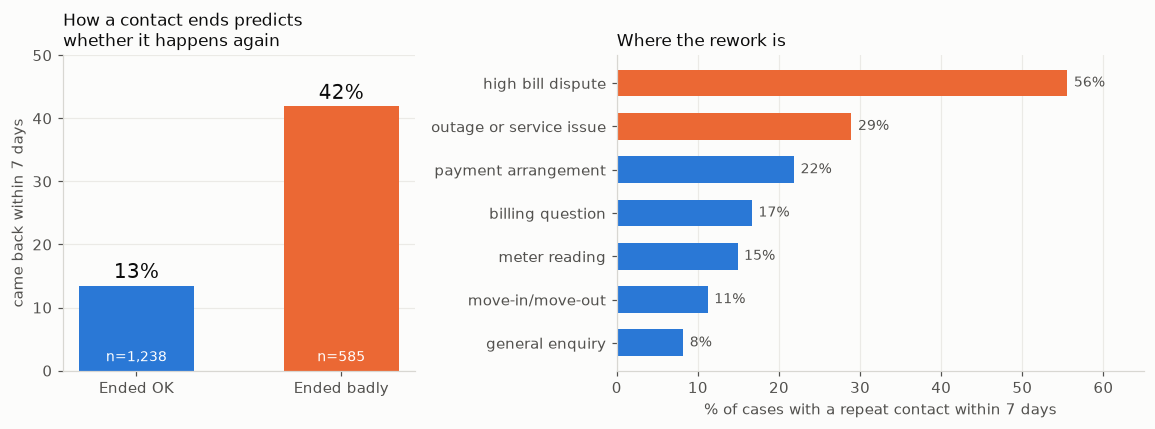

In [12]:
# --- Chart: the headline -------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.6, 4.0),
                               gridspec_kw={"width_ratios": [1, 1.5]})

vals = [ended.loc[False, "repeat_pct"] * 100, ended.loc[True, "repeat_pct"] * 100]
bars = ax1.bar(["Ended OK", "Ended badly"], vals, color=[BLUE, ORANGE], width=0.56)
for bar, v, n in zip(bars, vals, [ended.loc[False, "cases"], ended.loc[True, "cases"]]):
    ax1.text(bar.get_x() + bar.get_width() / 2, v + 1.2, f"{v:.0f}%",
             ha="center", fontsize=13, color=INK)
    ax1.text(bar.get_x() + bar.get_width() / 2, 1.5, f"n={n:,}",
             ha="center", fontsize=9, color="#ffffff")
ax1.set_ylim(0, 50)
ax1.set_ylabel("came back within 7 days")
ax1.set_title("How a contact ends predicts\nwhether it happens again",
              fontsize=11, color=INK, loc="left")
ax1.yaxis.grid(True, color="#ebeae6", linewidth=0.8)
ax1.set_axisbelow(True)

topic_rpt = (cases.groupby("topic_name")["is_repeat_contact_7d"].mean() * 100).sort_values()
ax2.barh(range(len(topic_rpt)), topic_rpt.values,
         color=[ORANGE if v > 25 else BLUE for v in topic_rpt.values], height=0.62)
for i, v in enumerate(topic_rpt.values):
    ax2.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=9, color=MUTED)
ax2.set_yticks(range(len(topic_rpt)), topic_rpt.index)
ax2.set_xlim(0, 65)
ax2.set_xlabel("% of cases with a repeat contact within 7 days")
ax2.set_title("Where the rework is", fontsize=11, color=INK, loc="left")
ax2.xaxis.grid(True, color="#ebeae6", linewidth=0.8)
ax2.set_axisbelow(True)

fig.tight_layout()
plt.show()

**Contacts that end badly come back at 41.9%. Contacts that end well come back at
13.5%.** Three times the rate, on 585 contacts.

Hold time, by comparison, barely moves it: 26.5% against 22.1%. Hold makes a call
*feel* worse — it showed up in the driver model — but it is how the call **ends**
that decides whether the customer has to ring again.

That distinction is the whole recommendation. The lever is not "be faster". It is
"do not hang up while the customer is still unresolved."

In [13]:
# --- Sizing the prize ----------------------------------------------------
# Deliberately conservative: closing a THIRD of the gap, not all of it.
bad_cases = int(ended.loc[True, "cases"])
bad_rate, good_rate = ended.loc[True, "repeat_pct"], ended.loc[False, "repeat_pct"]
avg_handle = df["handle_time_sec"].mean()

current = bad_cases * bad_rate
for share in [1/3, 1/2]:
    improved = bad_cases * (bad_rate - (bad_rate - good_rate) * share)
    saved = current - improved
    print(f"Closing {share:.0%} of the gap: {saved:.0f} fewer repeat contacts "
          f"per 6 months ({saved * avg_handle / 3600:.0f} agent-hours), "
          f"repeat rate {cases['is_repeat_contact_7d'].mean():.1%} → "
          f"{(cases['is_repeat_contact_7d'].sum() - saved) / len(cases):.1%}")

print(f"\nFor scale: {len(df):,} contacts over 6 months, "
      f"{cases['is_repeat_contact_7d'].sum():.0f} repeat contacts, "
      f"mean handle time {avg_handle / 60:.1f} min.")
print("Scale linearly for a real centre's volume.")

Closing 33% of the gap: 55 fewer repeat contacts per 6 months (8 agent-hours), repeat rate 22.6% → 19.6%
Closing 50% of the gap: 83 fewer repeat contacts per 6 months (12 agent-hours), repeat rate 22.6% → 18.0%

For scale: 2,000 contacts over 6 months, 412 repeat contacts, mean handle time 8.3 min.
Scale linearly for a real centre's volume.


## 4. What this adds up to

**The problem is not speed, and it is not channel.** Channel has no measurable
effect, and hold time — though worth fixing — moves repeat contacts by four points.
How a conversation *ends* moves them by twenty-eight.

**Three numbers for the recommendation:**

| | |
|---|---|
| Contacts ending badly come back at **41.9%** vs **13.5%** | **3.1×** the rework |
| Outage calls carry **5.5×** the odds of going negative; channel carries **1.06×** | target the work, not the medium |
| Team 3: **−10.4pp** negative and **+7pp** FCR while the rest of the centre moved **−1.4pp** | it is fixable, and someone here already did it |

**And one caution.** Nothing in this data explains *why* Team 3 improved. Find out
before designing anything — the answer is in that team, not in these tables.

→ `docs/recommendation.md`